# Multi-agent RL: a wolf pack learns to hunt

Three **wolves** hunt a **deer** in a 9×9 meadow with a few rocks. The deer is a little faster than a wolf (a bonus move every 3rd step), so a single wolf chasing it can never catch it. **The wolves only land bites when the deer has no escape route left**, so they have to work together to trap it:

| situation | wolves needed |
|---|---|
| pinned in a **corner** | 2 |
| pinned against an **edge** (or a rock) | 3 |
| surrounded in the **open** | 4, which a pack of 3 can only manage by also using rocks |

The deer has 5 health. Every wolf next to a trapped deer bites once per step, so 3 wolves around a cornered deer finish it quickly.

**The deer** is not learning. It follows a clever fixed rule: move to wherever it "owns" the most of the meadow, meaning cells it can reach before any wolf. That keeps it in open space and away from corners, so naive chasing usually fails. It never stands still next to a wolf. A deer frozen in open ground can't be trapped by 3 wolves (that takes 4), so standing still would make it unbeatable.

**The wolves** learn with DQN, the same algorithm as the gridworld notebook, plus two standard multi-agent ideas:
- **Parameter sharing:** all three wolves use **one** network. Each wolf feeds it the world as seen from its own position and gets its own action back. One brain, three bodies, and every wolf's experience trains that same brain.
- **Team reward:** every bite rewards **all** wolves, not just the biter. A wolf that blocks the deer's last exit gets credit for the bite its packmate lands, which is what makes teamwork pay.

In [1]:
import json, uuid
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from collections import deque
from IPython.display import HTML, display

rng = np.random.default_rng(0)
torch.manual_seed(0)

## 1. Sprites
Simple hand-written SVG sprites. The animations below move them around a grass background. All sprites face right; they get mirrored when an animal moves left.

In [2]:
CELL = 44   # pixels per grid cell in the drawings (the grass tile below matches it)

SPRITES = """<svg width="0" height="0" style="position:absolute"><defs>
<pattern id="grass" width="44" height="44" patternUnits="userSpaceOnUse">
  <rect width="44" height="44" fill="#cfe8b0"/>
  <path d="M8,30 l2,-6 l2,6 M28,14 l2,-6 l2,6 M34,38 l2,-5 l2,5 M16,10 l1.5,-4 l1.5,4"
        stroke="#94c46f" stroke-width="1.5" fill="none"/>
</pattern>

<symbol id="wolf" viewBox="-50 -50 100 100">
  <path d="M-28,-4 Q-46,-8 -46,-26 Q-36,-12 -24,-12 Z" fill="#59616b" stroke="#2b3036" stroke-width="2.5" stroke-linejoin="round"/>
  <rect x="-22" y="6" width="8" height="26" rx="3" fill="#4a5058" stroke="#2b3036" stroke-width="2"/>
  <rect x="-10" y="6" width="8" height="26" rx="3" fill="#6b7480" stroke="#2b3036" stroke-width="2"/>
  <rect x="10" y="6" width="8" height="26" rx="3" fill="#4a5058" stroke="#2b3036" stroke-width="2"/>
  <rect x="21" y="6" width="8" height="26" rx="3" fill="#6b7480" stroke="#2b3036" stroke-width="2"/>
  <ellipse cx="0" cy="-2" rx="30" ry="15" fill="#6b7480" stroke="#2b3036" stroke-width="2.5"/>
  <ellipse cx="2" cy="7" rx="19" ry="5" fill="#a7afb8"/>
  <path d="M22,-14 L25,-36 L33,-20 Z" fill="#59616b" stroke="#2b3036" stroke-width="2" stroke-linejoin="round"/>
  <path d="M31,-18 L37,-38 L42,-17 Z" fill="#59616b" stroke="#2b3036" stroke-width="2" stroke-linejoin="round"/>
  <circle cx="33" cy="-10" r="12" fill="#6b7480" stroke="#2b3036" stroke-width="2.5"/>
  <path d="M38,-15 L49,-8 L46,-1 L36,-1 Z" fill="#a7afb8" stroke="#2b3036" stroke-width="2" stroke-linejoin="round"/>
  <circle cx="47" cy="-7" r="2.6" fill="#111"/>
  <circle cx="35" cy="-14" r="2.4" fill="#ffd23f" stroke="#111" stroke-width="1"/>
</symbol>

<symbol id="deer" viewBox="-50 -50 100 100">
  <rect x="-22" y="2" width="5" height="32" rx="2" fill="#7a4e28"/>
  <rect x="-13" y="2" width="5" height="32" rx="2" fill="#94603a"/>
  <rect x="13" y="2" width="5" height="32" rx="2" fill="#7a4e28"/>
  <rect x="21" y="2" width="5" height="32" rx="2" fill="#94603a"/>
  <path d="M-23,31 h7 v4 h-7 Z M-14,31 h7 v4 h-7 Z M12,31 h7 v4 h-7 Z M20,31 h7 v4 h-7 Z" fill="#2b1a0e"/>
  <ellipse cx="0" cy="-2" rx="28" ry="13" fill="#b9814a" stroke="#5e3b1c" stroke-width="2.5"/>
  <ellipse cx="-30" cy="-8" rx="6" ry="5" fill="#fff8ec" stroke="#5e3b1c" stroke-width="2"/>
  <circle cx="-8" cy="-8" r="2.2" fill="#fff8ec"/><circle cx="2" cy="-10" r="2.2" fill="#fff8ec"/>
  <circle cx="-3" cy="-4" r="1.8" fill="#fff8ec"/><circle cx="8" cy="-5" r="1.8" fill="#fff8ec"/>
  <path d="M16,-8 L25,-28 L34,-24 L27,-2 Z" fill="#b9814a" stroke="#5e3b1c" stroke-width="2.5" stroke-linejoin="round"/>
  <path d="M28,-34 L22,-46 M25,-40 L17,-43 M33,-35 L38,-48 M36,-42 L44,-45"
        stroke="#6b4423" stroke-width="3" stroke-linecap="round" fill="none"/>
  <ellipse cx="35" cy="-28" rx="11" ry="7.5" fill="#c99560" stroke="#5e3b1c" stroke-width="2.5"/>
  <ellipse cx="24" cy="-33" rx="6" ry="3" fill="#b9814a" stroke="#5e3b1c" stroke-width="2" transform="rotate(-30 24 -33)"/>
  <circle cx="45" cy="-27" r="2.4" fill="#2b1a0e"/>
  <circle cx="36" cy="-30" r="2" fill="#2b1a0e"/>
</symbol>

<symbol id="rock" viewBox="-50 -50 100 100">
  <path d="M-38,30 L-42,4 L-24,-24 L6,-34 L32,-18 L42,10 L34,32 Z" fill="#8d8f94" stroke="#4a4c50" stroke-width="3" stroke-linejoin="round"/>
  <path d="M-24,-20 L4,-29 L22,-18 L0,-12 Z" fill="#b4b6ba"/>
  <path d="M-10,8 L10,2 L22,14" stroke="#5f6166" stroke-width="2.5" fill="none"/>
</symbol>

<symbol id="bite" viewBox="-50 -50 100 100">
  <polygon points="0,-46 11,-16 42,-24 20,0 44,22 12,16 0,46 -12,16 -44,22 -20,0 -42,-24 -11,-16"
           fill="#ff3b30" stroke="#8b0000" stroke-width="3" stroke-linejoin="round"/>
  <polyline points="-18,-6 -12,8 -6,-6 0,8 6,-6 12,8 18,-6" fill="none" stroke="#fff" stroke-width="4" stroke-linejoin="round"/>
</symbol>
</defs></svg>"""

def sprite_box(name, label):
    return (f'<div style="text-align:center"><svg width="96" height="96"><rect width="96" height="96" rx="8" fill="url(#grass)"/>'
            f'<use href="#{name}" x="8" y="8" width="80" height="80"/></svg><div>{label}</div></div>')

display(HTML(SPRITES + '<div style="display:flex;gap:24px">' +
             "".join(sprite_box(n, l) for n, l in [("wolf", "wolf"), ("deer", "deer"), ("rock", "rock"), ("bite", "bite!")]) + "</div>"))

## 2. The hunt: rules, the deer's brain, and what each wolf sees

In [3]:
SIZE         = 16          # meadow is SIZE x SIZE
N_WOLVES     = 3 
ROCK_DENSITY = 0.11 #0.06      # chance each cell is a rock
DEER_HP      = 5
MAX_STEPS    = 80
DEER_RANDOM  = 0.05       # chance per step the deer panics and moves randomly
DEER_EXTRA_EVERY = 3      # the deer is a bit faster: a bonus move every N steps (0 = never)
SPOOK_DIST   = 1          # the deer won't stand still with a wolf this close
BITE_MAX_EXITS = 0        # bites land only when the deer has at most this many open exits
VIEW         = 6  #3      # each wolf sees rocks within 6 cells of itself

# Rewards (shared by the whole pack unless noted)
BITE_REWARD, KILL_REWARD, STEP_COST = 1.0, 10.0, 0.01
CHASE_SHAPING = 0.1       # per wolf: +0.1 for each cell it moves closer to the deer
PIN_SHAPING   = 0.2       #kind of hacky, but speeds up training significantly      # team: +0.2 for each of the deer's exits the pack closes off

ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1), (0, 0)]   # up, down, left, right, stay
GRID_R, GRID_C = np.mgrid[:SIZE, :SIZE]

def dist(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def connected(rocks):
    """True if every open cell can reach every other one (no sealed-off pockets)."""
    free = [tuple(p) for p in np.argwhere(~rocks)]
    seen, queue = {free[0]}, deque([free[0]])
    while queue:
        r, c = queue.popleft()
        for dr, dc in ACTIONS[:4]:
            n = (r + dr, c + dc)
            if 0 <= n[0] < SIZE and 0 <= n[1] < SIZE and not rocks[n] and n not in seen:
                seen.add(n); queue.append(n)
    return len(seen) == len(free)

def random_arena(rng):
    """Random rocks, a deer, and wolves starting at least 4 steps away from it."""
    while True:
        rocks = rng.random((SIZE, SIZE)) < ROCK_DENSITY
        if not connected(rocks):
            continue
        free = [tuple(int(v) for v in p) for p in np.argwhere(~rocks)]
        order = rng.permutation(len(free))
        deer = free[order[0]]
        wolves = [free[i] for i in order[1:] if dist(free[i], deer) >= 4][:N_WOLVES]
        if len(wolves) == N_WOLVES:
            return rocks, deer, wolves


class Hunt:
    def __init__(self, rocks, deer, wolves):
        self.rocks, self.deer0, self.wolves0 = rocks, deer, wolves
        self.padded = np.pad(rocks.astype(np.float32), VIEW, constant_values=1)   # off-map = rock
        self.reset()

    def reset(self):
        self.deer, self.wolves, self.hp, self.t, self.bites = self.deer0, list(self.wolves0), DEER_HP, 0, []
        return self.observe()

    def blocked(self, p, ignore_wolf=None):
        r, c = p
        if not (0 <= r < SIZE and 0 <= c < SIZE) or self.rocks[r, c]:
            return True
        return any(w == p for i, w in enumerate(self.wolves) if i != ignore_wolf)

    def exits(self, p=None):
        """For each direction (up, down, left, right): is that neighbour of the deer open?"""
        p = self.deer if p is None else p
        return [not self.blocked((p[0] + dr, p[1] + dc)) for dr, dc in ACTIONS[:4]]

    # ---- the deer's brain (fixed rule, not learned) ----
    def territory(self, p):
        """Cells the deer at p could reach before any wolf (straight-line grid distance)."""
        W = np.array(self.wolves)
        wolf_d = (np.abs(GRID_R[..., None] - W[:, 0]) + np.abs(GRID_C[..., None] - W[:, 1])).min(-1)
        return (np.abs(GRID_R - p[0]) + np.abs(GRID_C - p[1]) < wolf_d) & ~self.rocks

    def deer_options(self):
        return [self.deer] + [(self.deer[0] + dr, self.deer[1] + dc)
                              for (dr, dc), ok in zip(ACTIONS[:4], self.exits()) if ok]

    def deer_move(self):
        options = self.deer_options()
        if len(options) > 1 and min(dist(w, self.deer) for w in self.wolves) <= SPOOK_DIST:
            options = options[1:]                       # a wolf is right there: no standing still
        if rng.random() < DEER_RANDOM:
            return options[rng.integers(len(options))]
        score = lambda p: self.territory(p).sum() + 0.5 * sum(self.exits(p)) + 0.1 * rng.random()
        return max(options, key=score)

    # ---- what each wolf sees ----
    def observe(self):
        """One row per wolf, from that wolf's point of view."""
        exits = np.array(self.exits(), np.float32)
        rows = []
        for i, (r, c) in enumerate(self.wolves):
            deer_offset = [(self.deer[0] - r) / SIZE, (self.deer[1] - c) / SIZE]
            packmates = sorted((w for j, w in enumerate(self.wolves) if j != i), key=lambda w: dist(w, self.deer))
            pack_offsets = [v for w in packmates for v in ((w[0] - r) / SIZE, (w[1] - c) / SIZE)]
            nearby_rocks = self.padded[r:r + 2 * VIEW + 1, c:c + 2 * VIEW + 1].ravel()
            rows.append(np.concatenate([[r / SIZE, c / SIZE], deer_offset, exits, pack_offsets,
                                        nearby_rocks, [self.hp / DEER_HP]]))
        return np.array(rows, np.float32)

    # ---- one tick of the hunt ----
    def step(self, actions):
        """All wolves move, bites are checked, then the deer flees.
        Returns (obs, per-wolf rewards, terminal, outcome)."""
        old_dist = [dist(w, self.deer) for w in self.wolves]
        old_exits = sum(self.exits())
        for i in rng.permutation(N_WOLVES):            # wolves move one at a time, in random order
            dr, dc = ACTIONS[actions[i]]
            target = (self.wolves[i][0] + dr, self.wolves[i][1] + dc)
            if target != self.deer and not self.blocked(target, ignore_wolf=i):
                self.wolves[i] = target
        self.t += 1

        exits = sum(self.exits())
        trapped = exits <= BITE_MAX_EXITS
        self.bites = [w for w in self.wolves if trapped and dist(w, self.deer) == 1]
        self.hp -= len(self.bites)

        team = BITE_REWARD * len(self.bites) + PIN_SHAPING * (old_exits - exits) - STEP_COST
        rewards = np.array([team + CHASE_SHAPING * (old_dist[i] - dist(w, self.deer))
                            for i, w in enumerate(self.wolves)], np.float32)
        if self.hp <= 0:
            return self.observe(), rewards + KILL_REWARD, True, "kill"

        self.deer = self.deer_move()
        if DEER_EXTRA_EVERY and self.t % DEER_EXTRA_EVERY == 0:
            self.deer = self.deer_move()
        return self.observe(), rewards, False, "escaped" if self.t >= MAX_STEPS else None

OBS_DIM = Hunt(*random_arena(rng)).observe().shape[1]
print("each wolf sees", OBS_DIM, "numbers")

each wolf sees 182 numbers


**What each wolf sees** (all relative to itself, so the same network works for every wolf):
- its own position, and the deer's offset from it
- which of the deer's 4 exits are still open
- each packmate's offset, sorted by who is closest to the deer
- rocks within 2 cells (off-map counts as rock)
- the deer's remaining health

### When does a bite land?

In [4]:
def board_svg(uid, rocks, deer, wolves, bites=(), cell=CELL):
    """One meadow as SVG. deer = (r, c[, facing]); wolves = [(r, c[, facing])]; bites = [(y, x)] in cell units.
    Each animal is a <g class="mover"> that the animation player slides around."""
    rows, cols = rocks.shape
    W, H = cols * cell, rows * cell
    s = [f'<svg id="{uid}" width="{W}" height="{H}" viewBox="0 0 {W} {H}" style="border-radius:6px;display:block">',
         f'<rect width="{W}" height="{H}" fill="url(#grass)"/>']
    s += [f'<line x1="{c * cell}" y1="0" x2="{c * cell}" y2="{H}" stroke="#b9da9d"/>' for c in range(1, cols)]
    s += [f'<line x1="0" y1="{r * cell}" x2="{W}" y2="{r * cell}" stroke="#b9da9d"/>' for r in range(1, rows)]
    s += [f'<use href="#rock" x="{c * cell}" y="{r * cell}" width="{cell}" height="{cell}"/>' for r, c in np.argwhere(rocks)]

    def animal(name, el_id, r, c, facing=1):
        return (f'<g id="{el_id}" class="mover" style="transform:translate({(c + .5) * cell}px,{(r + .5) * cell}px)">'
                f'<g transform="scale({facing},1)"><use href="#{name}" x="{-cell / 2}" y="{-cell / 2}" '
                f'width="{cell}" height="{cell}"/></g></g>')
    s.append(animal("deer", f"{uid}_deer", *deer))
    s += [animal("wolf", f"{uid}_w{i}", *w) for i, w in enumerate(wolves)]
    for i in range(len(wolves)):                       # bite bursts, hidden unless a bite happens
        y, x = bites[i] if i < len(bites) else (-9, -9)
        s.append(f'<use id="{uid}_b{i}" href="#bite" x="{(x + .5) * cell - cell * .3}" y="{(y + .5) * cell - cell * .3}" '
                 f'width="{cell * .6}" height="{cell * .6}" visibility="{"visible" if i < len(bites) else "hidden"}"/>')
    return "".join(s) + "</svg>"

def facing(frm, to, default=1):
    return 1 if to[1] > frm[1] else -1 if to[1] < frm[1] else default

def example(deer, wolves, rock_cells=(), n=4):
    rocks = np.zeros((n, n), bool)
    for p in rock_cells: rocks[p] = True
    exits = sum(not (not (0 <= deer[0] + dr < n and 0 <= deer[1] + dc < n) or rocks[deer[0] + dr, deer[1] + dc]
                     or (deer[0] + dr, deer[1] + dc) in wolves) for dr, dc in ACTIONS[:4])
    bites = [((w[0] + deer[0]) / 2, (w[1] + deer[1]) / 2) for w in wolves] if exits <= BITE_MAX_EXITS else []
    return board_svg(uuid.uuid4().hex, rocks, deer, [(*w, facing(w, deer)) for w in wolves], bites, cell=40), exits

cases = [("Pinned in a corner<br>2 wolves → <b>BITE</b>", (0, 0), [(0, 1), (1, 0)], ()),
         ("Pinned against the edge<br>3 wolves → <b>BITE</b>", (0, 2), [(0, 1), (0, 3), (1, 2)], ()),
         ("Using a rock as a 4th wall<br>3 wolves → <b>BITE</b>", (2, 2), [(2, 1), (2, 3), (3, 2)], [(1, 2)]),
         ("One exit left<br><b>no bite</b>: it escapes upward", (2, 2), [(2, 1), (2, 3), (3, 2)], ())]
html = '<div style="display:flex;gap:18px;flex-wrap:wrap">'
for label, d, ws, rk in cases:
    svg, ex = example(d, ws, rk)
    html += f'<div style="text-align:center">{svg}<div style="margin-top:4px">{label}</div></div>'
display(HTML(SPRITES + html + "</div>"))

### The deer's brain
The deer looks at each move it could make (including standing still, unless a wolf is right next to it), counts how many cells it would **own**, meaning cells it could reach before any wolf, and picks the move with the most. Wolves that all chase from the same side just push it into open space. To trap it, the pack has to spread out and shrink its territory from several sides.

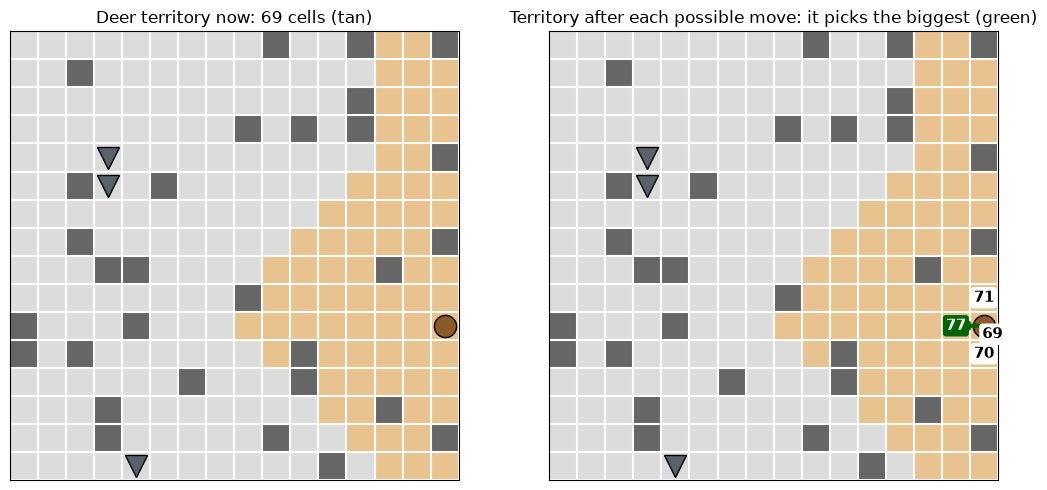

In [5]:
env = Hunt(*random_arena(np.random.default_rng(17)))
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
own = env.territory(env.deer)
for ax in axes:
    ax.imshow(np.where(env.rocks, 2, own.astype(int)), cmap=ListedColormap(["#dcdcdc", "#e8c38f", "#666666"]), vmin=0, vmax=2)
    ax.plot(env.deer[1], env.deer[0], "o", ms=16, color="#8a5a2b", mec="k")
    for w in env.wolves:
        ax.plot(w[1], w[0], "v", ms=16, color="#59616b", mec="k")
    ax.set_xticks(np.arange(-.5, SIZE), minor=True); ax.set_yticks(np.arange(-.5, SIZE), minor=True)
    ax.grid(which="minor", color="white", lw=1.5); ax.tick_params(which="both", length=0, labelbottom=False, labelleft=False)
axes[0].set_title(f"Deer territory now: {env.territory(env.deer).sum()} cells (tan)")
scores = {o: env.territory(o).sum() for o in env.deer_options()}
best = max(scores, key=scores.get)
for o, s in scores.items():
    y, x = (o[0] + .3, o[1] + .3) if o == env.deer else o          # "stay" label sits beside the deer
    axes[1].text(x, y, str(s), ha="center", va="center", fontsize=11, fontweight="bold", zorder=5,
                 color="white" if o == best else "k",
                 bbox=dict(boxstyle="round,pad=0.2", fc="darkgreen" if o == best else "white", ec="none"))
axes[1].annotate("", xy=(best[1], best[0]), xytext=(env.deer[1], env.deer[0]),
                 arrowprops=dict(arrowstyle="->", lw=3, color="darkgreen") if best != env.deer else None)
axes[1].set_title("Territory after each possible move: it picks the biggest (green)")
plt.tight_layout(); plt.show()

## 3. Baselines
Before training, two non-learning packs:
- **random wolves**
- **chasing wolves**: each wolf greedily steps toward the deer. This is the obvious strategy, and it's what the learned pack needs to beat.

In [6]:
def chase_policy(obs, env):
    acts = []
    for w in env.wolves:
        def cost(a):
            n = (w[0] + ACTIONS[a][0], w[1] + ACTIONS[a][1])
            return (99 if env.blocked(n) else dist(n, env.deer)) + 0.1 * rng.random()
        acts.append(min(range(len(ACTIONS)), key=cost))
    return acts

random_policy = lambda obs, env: rng.integers(len(ACTIONS), size=N_WOLVES)

def run_hunt(env, policy):
    """Play one hunt. Returns (outcome, steps, bites, frames) with frames ready for the animation player."""
    obs = env.reset()
    face = {"deer": 1, **{i: facing(w, env.deer) for i, w in enumerate(env.wolves)}}
    def snap(prev_deer, prev_wolves, end=None):
        face["deer"] = facing(prev_deer, env.deer, face["deer"])
        for i, (a, b) in enumerate(zip(prev_wolves, env.wolves)):
            face[i] = facing(a, b, face[i])
        return {"deer": [*env.deer, face["deer"]], "wolves": [[*w, face[i]] for i, w in enumerate(env.wolves)],
                "hp": max(env.hp, 0), "bites": [[(w[0] + env.deer[0]) / 2, (w[1] + env.deer[1]) / 2] for w in env.bites],
                "end": end, "t": env.t}
    frames, total_bites = [snap(env.deer, env.wolves)], 0
    while True:
        prev_deer, prev_wolves = env.deer, list(env.wolves)
        obs, _, _, outcome = env.step(policy(obs, env))
        total_bites += len(env.bites)
        frames.append(snap(prev_deer, prev_wolves, outcome))
        if outcome:
            return outcome, env.t, total_bites, frames

def evaluate(policy, arenas):
    res = [run_hunt(Hunt(*a), policy) for a in arenas]
    kills = [s for o, s, _, _ in res if o == "kill"]
    return {"kill rate": len(kills) / len(res), "bites per hunt": np.mean([b for _, _, b, _ in res]),
            "steps to kill": np.mean(kills) if kills else np.nan}

TEST_ARENAS = [random_arena(np.random.default_rng(1000 + i)) for i in range(100)]   # never trained on
baseline = {name: evaluate(p, TEST_ARENAS) for name, p in [("random", random_policy), ("chase", chase_policy)]}
for name, r in baseline.items():
    print(f"{name:7s}", {k: round(v, 2) for k, v in r.items()})

random  {'kill rate': 0.0, 'bites per hunt': np.float64(0.0), 'steps to kill': nan}
chase   {'kill rate': 0.22, 'bites per hunt': np.float64(1.23), 'steps to kill': np.float64(38.59)}


## 4. Training the pack (shared DQN)

Same DQN as the gridworld notebook: a Q-network, a replay buffer, a target network and epsilon-greedy exploration. The multi-agent twist is that every step produces **3 transitions**, one per wolf, each from that wolf's point of view, and all of them train the same network.

Every 250 hunts the pack is tested (no exploration) on 100 meadows it never trains on. Training takes about 3-4 minutes on a CPU.

In [ ]:
def make_net(hidden=128):
    return nn.Sequential(nn.Linear(OBS_DIM, hidden), nn.ReLU(),
                         nn.Linear(hidden, hidden), nn.ReLU(),
                         nn.Linear(hidden, len(ACTIONS)))

def act(net, obs, eps=0.0):
    """One action per wolf: each row of obs goes through the same network."""
    with torch.no_grad():
        greedy = net(torch.from_numpy(obs)).argmax(1).numpy()
    explore = rng.random(len(obs)) < eps
    return np.where(explore, rng.integers(len(ACTIONS), size=len(obs)), greedy)

class Replay:
    def __init__(self, n=100_000):
        self.o, self.o2 = np.zeros((n, OBS_DIM), np.float32), np.zeros((n, OBS_DIM), np.float32)
        self.a, self.r, self.d = np.zeros(n, np.int64), np.zeros(n, np.float32), np.zeros(n, np.float32)
        self.n, self.i, self.size = n, 0, 0
    def add(self, o, a, r, o2, d):
        for k in range(len(o)):                         # one transition per wolf
            self.o[self.i], self.a[self.i], self.r[self.i], self.o2[self.i], self.d[self.i] = o[k], a[k], r[k], o2[k], d
            self.i, self.size = (self.i + 1) % self.n, min(self.size + 1, self.n)
    def sample(self, k):
        idx = rng.integers(self.size, size=k)
        return [torch.from_numpy(x[idx]) for x in (self.o, self.a, self.r, self.o2, self.d)]

# Laptop train time: 6m 15s
# Episodes to beat the naive approach: ~5000 (PIN_SHAPING on)
def train(episodes=3500, gamma=0.95, lr=5e-4, batch=128, update_every=2, eps_end=0.05,
          sync_every=500, eval_every=250):
    net, target = make_net(), make_net()
    target.load_state_dict(net.state_dict())
    opt, buf = torch.optim.Adam(net.parameters(), lr=lr, foreach=True), Replay()
    history, steps = [], 0
    for ep in range(episodes):
        eps = max(eps_end, 1 - ep / (0.6 * episodes))
        env = Hunt(*random_arena(rng))                   # a new meadow every hunt
        obs = env.reset()
        while True:
            a = act(net, obs, eps)
            obs2, r, terminal, outcome = env.step(a)
            buf.add(obs, a, r, obs2, terminal)
            obs, steps = obs2, steps + 1
            if buf.size >= 1000 and steps % update_every == 0:
                o, a_, r_, o2, d = buf.sample(batch)
                q = net(o).gather(1, a_[:, None]).squeeze(1)
                with torch.no_grad():
                    y = r_ + gamma * (1 - d) * target(o2).max(1).values
                loss = nn.functional.smooth_l1_loss(q, y)
                opt.zero_grad(); loss.backward(); opt.step()
            if steps % sync_every == 0:
                target.load_state_dict(net.state_dict())
            if outcome: break
        if (ep + 1) % eval_every == 0:
            res = evaluate(lambda o, e: act(net, o), TEST_ARENAS)
            history.append((ep + 1, res["kill rate"], res["bites per hunt"]))
            print(f"hunt {ep + 1:5d}  eps={eps:.2f}  kill rate={res['kill rate']:.0%}  bites/hunt={res['bites per hunt']:.2f}")
    return net, history

net, history = train()

hunt   250  eps=0.88  kill rate=0%  bites/hunt=0.00
hunt   500  eps=0.76  kill rate=3%  bites/hunt=0.15
hunt   750  eps=0.64  kill rate=6%  bites/hunt=0.37
hunt  1000  eps=0.52  kill rate=7%  bites/hunt=0.41
hunt  1250  eps=0.41  kill rate=15%  bites/hunt=0.81
hunt  1500  eps=0.29  kill rate=18%  bites/hunt=1.02
hunt  1750  eps=0.17  kill rate=17%  bites/hunt=1.09
hunt  2000  eps=0.05  kill rate=15%  bites/hunt=0.89
hunt  2250  eps=0.05  kill rate=16%  bites/hunt=0.89
hunt  2500  eps=0.05  kill rate=20%  bites/hunt=1.18
hunt  2750  eps=0.05  kill rate=19%  bites/hunt=1.13
hunt  3000  eps=0.05  kill rate=14%  bites/hunt=0.88
hunt  3250  eps=0.05  kill rate=16%  bites/hunt=0.94
hunt  3500  eps=0.05  kill rate=22%  bites/hunt=1.22


## 5. Learning curves

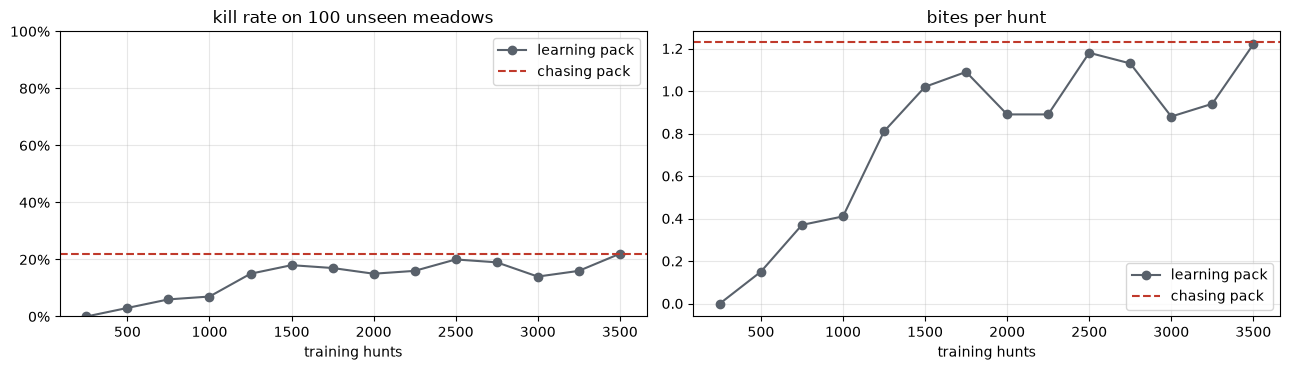

In [8]:
x, kill, bites = zip(*history)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8))
a1.plot(x, kill, "-o", color="#59616b", label="learning pack")
a1.axhline(baseline["chase"]["kill rate"], color="#c0392b", ls="--", label="chasing pack")
a1.set(title="kill rate on 100 unseen meadows", xlabel="training hunts", ylim=(0, 1))
a1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
a2.plot(x, bites, "-o", color="#59616b", label="learning pack")
a2.axhline(baseline["chase"]["bites per hunt"], color="#c0392b", ls="--", label="chasing pack")
a2.set(title="bites per hunt", xlabel="training hunts")
for a in (a1, a2): a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

## 6. Head to head on 200 new meadows

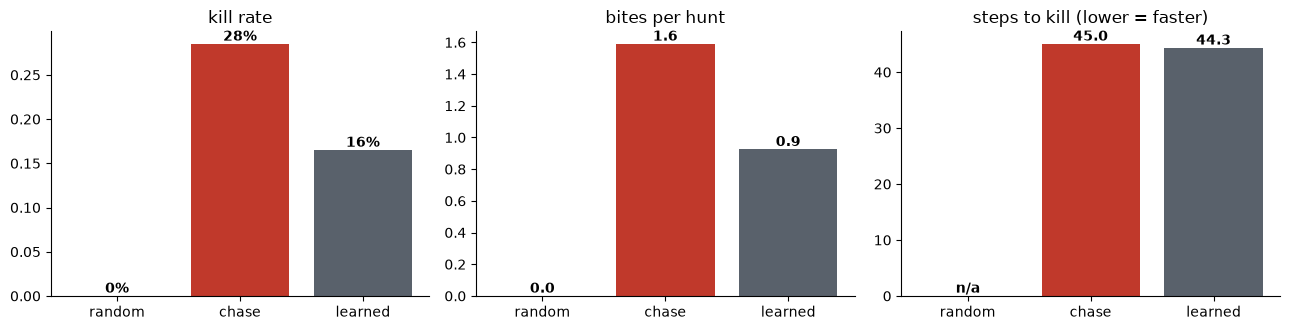

In [9]:
EVAL_ARENAS = [random_arena(np.random.default_rng(5000 + i)) for i in range(200)]
packs = {"random": random_policy, "chase": chase_policy, "learned": lambda o, e: act(net, o)}
results = {name: evaluate(p, EVAL_ARENAS) for name, p in packs.items()}

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
colors = ["#bbbbbb", "#c0392b", "#59616b"]
for ax, metric in zip(axes, ["kill rate", "bites per hunt", "steps to kill"]):
    vals = [results[n][metric] for n in packs]
    ax.bar(list(packs), np.nan_to_num(vals), color=colors)
    for i, v in enumerate(vals):
        ax.text(i, np.nan_to_num(v), "n/a" if np.isnan(v) else (f"{v:.0%}" if metric == "kill rate" else f"{v:.1f}"),
                ha="center", va="bottom", fontweight="bold")
    ax.set_title(metric + (" (lower = faster)" if metric == "steps to kill" else ""))
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 7. Watch the hunt
Each row puts the **chasing pack** and the **learned pack** on the same meadow. Red bursts are bites. Use the controls, and re-run the cell for new meadows.

The meadows shown are picked from ones where the learned pack made a kill, so you can watch its tactics. It doesn't always win (see the kill rate above). Set `ONLY_KILLS = False` for unfiltered random meadows.

In [10]:
PLAYER_JS = r"""
<script>
(function () {
  const D = __DATA__, C = __CELL__, uid = "__UID__", N = __N__;
  const slider = document.getElementById(uid + "_slider"), playBtn = document.getElementById(uid + "_play");
  let i = 0, timer = null;
  function place(el, r, c, f) {
    el.style.transform = "translate(" + (c + .5) * C + "px," + (r + .5) * C + "px)";
    el.firstChild.setAttribute("transform", "scale(" + f + ",1)");
  }
  function show(k) {
    i = k; slider.value = k;
    D.forEach(function (frames, p) {
      const f = frames[Math.min(k, frames.length - 1)], id = uid + "_" + p;
      const deer = document.getElementById(id + "_deer");
      place(deer, f.deer[0], f.deer[1], f.deer[2]);
      deer.style.opacity = f.end === "kill" ? 0.35 : 1;
      f.wolves.forEach(function (w, j) { place(document.getElementById(id + "_w" + j), w[0], w[1], w[2]); });
      f.wolves.forEach(function (w, j) {
        const b = document.getElementById(id + "_b" + j);
        if (j < f.bites.length) {
          b.setAttribute("x", (f.bites[j][1] + .5) * C - C * .3); b.setAttribute("y", (f.bites[j][0] + .5) * C - C * .3);
          b.setAttribute("visibility", "visible");
        } else b.setAttribute("visibility", "hidden");
      });
      let s = "step " + f.t + "  deer " + "\u2665".repeat(f.hp) + "\u2661".repeat(__HP__ - f.hp);
      if (f.bites.length) s += "  BITE x" + f.bites.length + "!";
      if (f.end === "kill") s += "  \u2014 KILL";
      if (f.end === "escaped") s += "  \u2014 deer escaped";
      document.getElementById(id + "_status").textContent = s;
    });
  }
  function stop() { clearInterval(timer); timer = null; playBtn.textContent = "\u25B6 play"; }
  playBtn.onclick = function () {
    if (timer) return stop();
    if (i >= N - 1) show(0);
    playBtn.textContent = "\u23F8 pause";
    timer = setInterval(function () { if (i >= N - 1) stop(); else show(i + 1); }, 380);
  };
  document.getElementById(uid + "_prev").onclick = function () { stop(); show(Math.max(0, i - 1)); };
  document.getElementById(uid + "_next").onclick = function () { stop(); show(Math.min(N - 1, i + 1)); };
  slider.oninput = function () { stop(); show(+slider.value); };
  show(0);
})();
</script>"""

def hunt_player(panels, columns=2):
    """panels: list of (title, rocks, frames). Draws all panels with one shared set of controls."""
    uid = "hunt" + uuid.uuid4().hex[:8]
    n = max(len(frames) for _, _, frames in panels)
    btn = 'style="padding:3px 10px;margin-right:6px;cursor:pointer"'
    html = [SPRITES, f"<style>#{uid} .mover {{ transition: transform 0.3s ease-in-out; }}</style>", f'<div id="{uid}">',
            f'<div style="margin-bottom:8px"><button id="{uid}_play" {btn}>&#9654; play</button>'
            f'<button id="{uid}_prev" {btn}>&#9664; step</button><button id="{uid}_next" {btn}>step &#9654;</button>'
            f'<input id="{uid}_slider" type="range" min="0" max="{n - 1}" value="0" style="width:300px;vertical-align:middle"></div>',
            f'<div style="display:grid;grid-template-columns:repeat({columns}, max-content);gap:14px 22px">']
    for p, (title, rocks, frames) in enumerate(panels):
        f0 = frames[0]
        html.append(f'<div><div style="font-weight:600;margin-bottom:3px">{title}</div>'
                    f'{board_svg(f"{uid}_{p}", rocks, f0["deer"], f0["wolves"])}'
                    f'<div id="{uid}_{p}_status" style="font-family:monospace;margin-top:3px"></div></div>')
    html.append("</div></div>")
    js = (PLAYER_JS.replace("__DATA__", json.dumps([frames for _, _, frames in panels]))
          .replace("__CELL__", str(CELL)).replace("__UID__", uid).replace("__N__", str(n)).replace("__HP__", str(DEER_HP)))
    return HTML("".join(html) + js)

ONLY_KILLS = True    # show meadows where the learned pack made a kill (False = any random meadow)

panels = []
while len(panels) < 4:                                          # re-run for new meadows
    arena = EVAL_ARENAS[rng.integers(len(EVAL_ARENAS))]
    learned = run_hunt(Hunt(*arena), packs["learned"])
    if ONLY_KILLS and learned[0] != "kill":
        continue
    chase = run_hunt(Hunt(*arena), packs["chase"])
    for name, (outcome, steps, n_bites, frames) in [("chase", chase), ("learned", learned)]:
        panels.append((f"{name} pack: {outcome} ({n_bites} bites)", arena[0], frames))
display(hunt_player(panels))

## Things to try
- **Train longer:** `train(episodes=6000)`. The kill rate is still climbing at 3000.
- `N_WOLVES = 4`: a pack of 4 can surround the deer in open ground. Chasing gets much better too, though.
- `BITE_MAX_EXITS = 1`: bites land when the deer has one exit left. Hunting becomes easy, and plain chasing works almost as well as learning.
- `DEER_RANDOM = 0`: a perfectly disciplined deer. `DEER_EXTRA_EVERY = 0` removes its speed edge, and plain chasing then wins about 75% of the time.
- `ROCK_DENSITY = 0.12`: more rocks to pin the deer against, but also more obstacles for the wolves.
- `PIN_SHAPING = 0`: remove the "close off its exits" hint and see whether the pack still discovers trapping.
- **Next step: make the deer learn too.** Train it with its own network against the pack. That's competitive multi-agent RL, where each side keeps adapting to the other.